# K-Nearest Neighbors: Predicting Job Satisfaction (NSCG 2023 + O*NET)

**Question:** Can a KNN classifier predict whether a college graduate is satisfied at work, and does adding person-job fit information improve on background factors alone?

**Data (already in this repo):**

| File | Rows | Used for |
|---|---|---|
| `data/college_grads_2023/nscg2023_clean.csv` | 79,800 employed respondents | Part 1: baseline vs. baseline + personal work values |
| `notebooks/possible data integration/nscg2023_onet30_2_subset.csv` | 6,849 respondents in 25 reviewed occupations | Part 2: adds O*NET 30.2 Work Values and fit features |

**Target:** `not_satisfied` = 1 if the person is somewhat or very dissatisfied with their job (about 10% of people), 0 if satisfied. This is the team's `satisfied` flag flipped, so the model focuses on the minority group we actually want to find. ROC AUC is the same either way.

**Leakage rule:** the `sat_*` columns (satisfaction with each job aspect) are never used as features. As the NSCG EDA notebook notes, they are almost the same question as overall satisfaction.

## Summary

| Sample | Model | Test ROC AUC (95% CI) | ΔAUC vs. baseline (95% CI) |
|---|---|---|---|
| Full NSCG, 79,800 | A. Baseline | 0.652 [0.638, 0.667] | |
| Full NSCG, 79,800 | B. + personal work values | 0.680 [0.667, 0.694] | **+0.028 [+0.018, +0.038]** |
| O*NET subset, 6,578 | A. Baseline | 0.626 [0.573, 0.677] | |
| O*NET subset, 6,578 | B. + personal work values | 0.668 [0.619, 0.715] | +0.042 [+0.001, +0.081] |
| O*NET subset, 6,578 | C. + occupation profile | 0.630 [0.577, 0.681] | +0.004 [−0.046, +0.051] |
| O*NET subset, 6,578 | D. + fit features | 0.634 [0.580, 0.684] | +0.008 [−0.051, +0.061] |

- **KNN is a weak but real predictor.** The baseline AUC of 0.65 is better than chance but far from strong, which is expected for a 90/10 target driven by many things a survey doesn't capture.
- **Personal work values help.** Adding the nine importance ratings improves AUC by about 0.03 on the full sample, and the confidence interval excludes zero. On the subset the gain is similar in size but less certain, since the test set has only 119 not-satisfied people.
- **O*NET fit features did not help KNN here.** Adding the occupation profile or the person-versus-job gaps did not improve AUC, and every interval includes zero. This is not evidence that fit doesn't matter. With only 25 occupations, O*NET adds very little variation, and KNN treats the extra columns as noise in its distance calculation.
- **KNN wants a very large k** (300 to 800 neighbors). With so few dissatisfied people, it needs a big neighborhood to estimate a probability. That makes KNN a smoothed lookup, not a sharp classifier.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
N_BOOT = 2000                      # bootstrap resamples for confidence intervals
K_GRID = [15, 51, 101, 201, 401, 601, 801, 1201]

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'college_grads_2023').is_dir())
CLEAN = ROOT / 'data/college_grads_2023/nscg2023_clean.csv'
SUBSET = ROOT / 'notebooks/possible data integration/nscg2023_onet30_2_subset.csv'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)

ASPECTS = ['ADV', 'BEN', 'CHAL', 'IND', 'LOC', 'RESP', 'SAL', 'SEC', 'SOC']
NUM_BASE = ['log_SALARY', 'HRSWK', 'AGE']
CAT_BASE = ['SEX_2023', 'RACETHM', 'DGRDG', 'EMSECSM', 'EMSIZE', 'OCEDRLP', 'SUPWK', 'MARIND']
IMP = [f'imp_{a}' for a in ASPECTS]          # personal work values: 4 = very important ... 1 = not important
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 2. Helper functions

KNN is distance based, so every numeric feature is standardized and every categorical feature is one-hot encoded inside a pipeline. The scaler is fit on training folds only, so no information leaks from the test set.

For each feature set we:
1. Hold out a stratified 20% test set (same split for every model, so comparisons are paired).
2. Tune `k` and the neighbor weighting with 5-fold stratified cross-validation on the training set, scoring by ROC AUC.
3. Pick a decision threshold from out-of-fold training predictions (the one that maximizes F1 for the not-satisfied class). The test set is never used to choose anything.
4. Report test ROC AUC with a 95% bootstrap confidence interval, survey-weighted AUC, PR AUC, and precision / recall / F1 for the not-satisfied class.

In [2]:
def make_pipeline(num, cat):
    pre = ColumnTransformer([('num', StandardScaler(), num),
                             ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
    return Pipeline([('pre', pre), ('knn', KNeighborsClassifier(n_jobs=-1))])


def fit_knn(data, y, train_idx, num, cat, k_grid=K_GRID):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    search = GridSearchCV(make_pipeline(num, cat),
                          {'knn__n_neighbors': k_grid, 'knn__weights': ['uniform', 'distance']},
                          scoring='roc_auc', cv=cv, n_jobs=1)
    search.fit(data.loc[train_idx], y[train_idx])
    # threshold from out-of-fold training predictions (never from the test set)
    oof = cross_val_predict(search.best_estimator_, data.loc[train_idx], y[train_idx],
                            cv=cv, method='predict_proba')[:, 1]
    grid = np.unique(np.round(oof, 4))
    f1s = [precision_recall_fscore_support(y[train_idx], oof >= t, average='binary', zero_division=0)[2] for t in grid]
    search.threshold_ = float(grid[int(np.argmax(f1s))])
    return search


def bootstrap_auc(y_true, p, rng):
    y_true, p = np.asarray(y_true), np.asarray(p)
    out = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].min() != y_true[i].max():
            out.append(roc_auc_score(y_true[i], p[i]))
    return np.percentile(out, [2.5, 97.5])


def evaluate(name, search, data, y, w, test_idx):
    p = search.predict_proba(data.loc[test_idx])[:, 1]
    yt = y[test_idx].to_numpy()
    lo, hi = bootstrap_auc(yt, p, np.random.default_rng(SEED))
    pred = (p >= search.threshold_).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(yt, pred, average='binary', zero_division=0)
    row = {'model': name,
           'best k': search.best_params_['knn__n_neighbors'],
           'weights': search.best_params_['knn__weights'],
           'CV AUC': round(search.best_score_, 3),
           'test AUC': round(roc_auc_score(yt, p), 3),
           'AUC 95% CI': f'[{lo:.3f}, {hi:.3f}]',
           'weighted AUC': round(roc_auc_score(yt, p, sample_weight=w[test_idx]), 3),
           'PR AUC': round(average_precision_score(yt, p), 3),
           'threshold': round(search.threshold_, 3),
           'precision': round(prec, 3), 'recall': round(rec, 3), 'F1': round(f1, 3)}
    return row, p


def paired_delta_auc(y_true, p_base, p_new, label):
    rng = np.random.default_rng(SEED)
    y_true = np.asarray(y_true)
    d = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].min() != y_true[i].max():
            d.append(roc_auc_score(y_true[i], p_new[i]) - roc_auc_score(y_true[i], p_base[i]))
    d = np.array(d)
    point = roc_auc_score(y_true, p_new) - roc_auc_score(y_true, p_base)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {'comparison': label, 'ΔAUC': round(point, 3), '95% CI': f'[{lo:+.3f}, {hi:+.3f}]',
            'share of bootstraps > 0': round((d > 0).mean(), 3)}


def plot_k_curves(searches, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, s in searches.items():
        r = pd.DataFrame(s.cv_results_)
        r = r[r.param_knn__weights == s.best_params_['knn__weights']]
        ax.errorbar(r.param_knn__n_neighbors.astype(int), r.mean_test_score, yerr=r.std_test_score,
                    marker='o', capsize=3, label=f"{name} ({s.best_params_['knn__weights']})")
    ax.set_xlabel('k (number of neighbors)'); ax.set_ylabel('5-fold CV ROC AUC')
    ax.set_title(title); ax.legend(frameon=False, fontsize=9)
    plt.tight_layout(); plt.show()

## 3. Part 1: full NSCG sample (79,800 people)

There are no O*NET features here yet, because only 25 occupations have been linked so far. This part answers a narrower question: do a person's own work values (`imp_*`, how important each of 9 job aspects is to them) add anything to background factors?

- **A. Baseline:** log salary, hours, age, sex, race/ethnicity, degree, employer sector and size, degree relatedness, supervisor, married (the team's `BASELINE` list).
- **B. Baseline + personal work values:** A plus the 9 `imp_*` ratings.

In [3]:
full = pd.read_csv(CLEAN, low_memory=False)
full['log_SALARY'] = np.log1p(full['SALARY'])           # salary is very right-skewed
for c in CAT_BASE:
    full[c] = full[c].astype(str)
y_full = 1 - full['satisfied']                           # 1 = not satisfied
w_full = full['WTSURVY']
print(f'{len(full):,} people, {y_full.mean():.1%} not satisfied')

train_f, test_f = train_test_split(full.index, test_size=0.2, stratify=y_full, random_state=SEED)
print(f'train {len(train_f):,}  test {len(test_f):,}')

79,800 people, 9.9% not satisfied
train 63,840  test 15,960


In [4]:
sets_full = {'A. Baseline': (NUM_BASE, CAT_BASE),
             'B. Baseline + personal values': (NUM_BASE + IMP, CAT_BASE)}
search_full, rows_full, probs_full = {}, [], {}
for name, (num, cat) in sets_full.items():
    search_full[name] = fit_knn(full, y_full, train_f, num, cat)
    row, probs_full[name] = evaluate(name, search_full[name], full, y_full, w_full, test_f)
    rows_full.append(row)
res_full = pd.DataFrame(rows_full).set_index('model')
res_full

,best k,weights,CV AUC,test AUC,AUC 95% CI,weighted AUC,PR AUC,threshold,precision,recall,F1
model,,,,,,,,,,,
A. Baseline,801,uniform,0.655,0.652,"[0.638, 0.667]",0.687,0.179,0.112,0.176,0.403,0.245
B. Baseline + personal values,801,distance,0.677,0.680,"[0.667, 0.694]",0.699,0.191,0.104,0.187,0.455,0.265


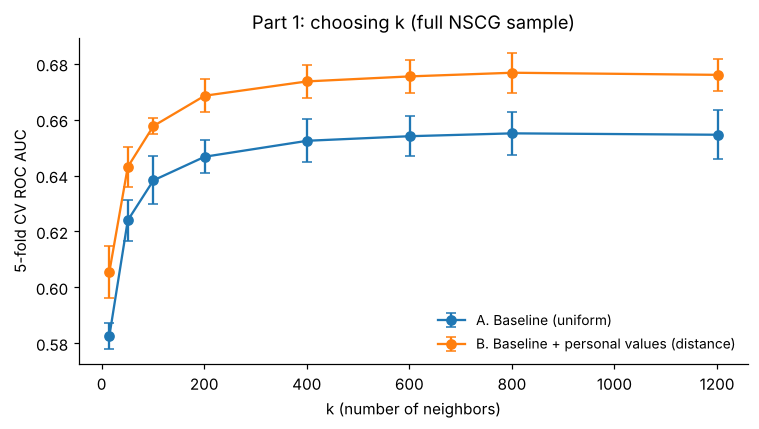

,ΔAUC,95% CI,share of bootstraps > 0
comparison,,,
B vs A: add personal work values,0.028,"[+0.018, +0.038]",1.0


In [5]:
plot_k_curves(search_full, 'Part 1: choosing k (full NSCG sample)')
yt = y_full[test_f].to_numpy()
pd.DataFrame([paired_delta_auc(yt, probs_full['A. Baseline'], probs_full['B. Baseline + personal values'],
                               'B vs A: add personal work values')]).set_index('comparison')

**Observation:** AUC rises quickly up to about k = 200 and then levels off. Past k ≈ 400 the differences are smaller than the fold-to-fold spread, so the exact best k (801) doesn't matter much. Model B beats A at every k, which makes the gain from personal work values a consistent pattern rather than a tuning accident. The paired bootstrap puts the improvement at +0.028 AUC, and B came out ahead in 100% of the 2,000 resamples.

Weighted AUC is a little higher than unweighted for both models (0.687 and 0.699), so the result holds when respondents are weighted to represent the population. KNN can't use survey weights during training, so weights are applied only in evaluation.

## 4. Part 2: O*NET-linked subset (25 occupations)

The integration notebook linked 6,849 respondents to O*NET 30.2 Work Values (extent scale `EX`, 1 to 7). That subset does not carry salary, hours, race, sector, employer size or marital status, so we match it back to `nscg2023_clean.csv` on survey weight, occupation, age, sex, degree, relatedness, supervisor, satisfaction and all nine importance ratings. This key is unique in the clean file. People without an exact match are dropped.

In [6]:
sub = pd.read_csv(SUBSET, low_memory=False)
sub['job_satisfaction'] = 5 - sub['JOBSATIS']
for a in ASPECTS:
    sub[f'imp_{a}'] = 5 - sub[f'FAC{a}']                 # same recoding as the EDA notebook
KEY = ['WTSURVY', 'N3OCPR', 'AGE', 'SEX_2023', 'DGRDG', 'OCEDRLP', 'SUPWK', 'job_satisfaction'] + IMP

clean_raw = pd.read_csv(CLEAN, low_memory=False)
assert not clean_raw.duplicated(KEY).any(), 'match key is not unique in the clean file'
extra = ['SALARY', 'HRSWK', 'RACETHM', 'EMSECSM', 'EMSIZE', 'MARIND', 'satisfied']
onet = sub.merge(clean_raw[KEY + extra], on=KEY, how='inner', validate='one_to_one')
print(f'matched {len(onet):,} of {len(sub):,} subset rows ({len(onet)/len(sub):.1%}); '
      f'{onet.ONET_SOC_CODE.nunique()} occupations')

onet['log_SALARY'] = np.log1p(onet['SALARY'])
for c in CAT_BASE:
    onet[c] = onet[c].astype(str)
y_on = 1 - onet['satisfied']
w_on = onet['WTSURVY']
print(f'{y_on.mean():.1%} not satisfied')

matched 6,578 of 6,849 subset rows (96.0%); 25 occupations
9.0% not satisfied


### 4.1 Fit features

O*NET rates what each occupation offers on six work values. NSCG asks how important nine job aspects are to the person. Following the mapping table in the NSCG EDA notebook (Section 9), each person's importance is averaged onto the O*NET value it matches. Both sides are rescaled to 0 to 1:

| O*NET work value | NSCG importance items |
|---|---|
| Achievement | intellectual challenge (`CHAL`) |
| Working Conditions | salary, benefits, job security (`SAL`, `BEN`, `SEC`) |
| Recognition | advancement (`ADV`) |
| Independence | independence, responsibility (`IND`, `RESP`) |
| Relationships | contribution to society (`SOC`) |

Support has no NSCG item and location has no O*NET value, so neither gets a gap. **This mapping is one reasonable choice for illustration. The team still needs to agree on its fit-scoring method.**

For each value, `gap = person importance − occupation level`. A positive gap means the job offers less than the person wants. `mean_abs_gap` sums up overall misfit.

In [7]:
ONET_WV = ['achievement', 'working_conditions', 'recognition', 'relationships', 'support', 'independence']
ONET_COLS = [f'ONET_WV_{v}' for v in ONET_WV]
MAP = {'achievement': ['CHAL'], 'working_conditions': ['SAL', 'BEN', 'SEC'],
       'recognition': ['ADV'], 'independence': ['IND', 'RESP'], 'relationships': ['SOC']}

GAPS = []
for value, items in MAP.items():
    person = (onet[[f'imp_{a}' for a in items]].mean(axis=1) - 1) / 3      # 1-4  -> 0-1
    job = (onet[f'ONET_WV_{value}'] - 1) / 6                                 # 1-7  -> 0-1
    onet[f'gap_{value}'] = person - job
    GAPS.append(f'gap_{value}')
onet['mean_abs_gap'] = onet[GAPS].abs().mean(axis=1)
FIT = GAPS + ['mean_abs_gap']
onet[FIT].describe().round(3)

,gap_achievement,gap_working_conditions,gap_recognition,gap_independence,gap_relationships,mean_abs_gap
count,6578.000,6578.000,6578.000,6578.000,6578.000,6578.000
mean,0.141,0.163,0.135,0.130,0.229,0.233
std,0.220,0.164,0.260,0.205,0.290,0.094
min,-0.833,-0.805,-0.833,-0.833,-0.833,0.022
25%,0.000,0.083,-0.055,0.000,0.112,0.166
50%,0.222,0.167,0.167,0.167,0.222,0.223
75%,0.278,0.278,0.333,0.278,0.500,0.289
max,0.583,0.570,0.667,0.612,0.833,0.700


### 4.2 Models

- **A. Baseline**, same as Part 1
- **B. + personal values** (`imp_*`)
- **C. + occupation profile**: B plus the six O*NET work values
- **D. + fit features**: C plus the five gaps and `mean_abs_gap`

With only 25 occupations, the O*NET columns take just 25 distinct value combinations, so in C they mostly act as an occupation identifier. D tests whether the person-versus-job comparison adds anything beyond that.

In [8]:
train_o, test_o = train_test_split(onet.index, test_size=0.2, stratify=y_on, random_state=SEED)
print(f'train {len(train_o):,}  test {len(test_o):,}  (test has {int(y_on[test_o].sum())} not-satisfied people)')

K_GRID_SMALL = [15, 31, 51, 101, 151, 201, 301, 401, 601]
sets_on = {'A. Baseline': (NUM_BASE, CAT_BASE),
           'B. + personal values': (NUM_BASE + IMP, CAT_BASE),
           'C. + occupation profile': (NUM_BASE + IMP + ONET_COLS, CAT_BASE),
           'D. + fit features': (NUM_BASE + IMP + ONET_COLS + FIT, CAT_BASE)}
search_on, rows_on, probs_on = {}, [], {}
for name, (num, cat) in sets_on.items():
    search_on[name] = fit_knn(onet, y_on, train_o, num, cat, K_GRID_SMALL)
    row, probs_on[name] = evaluate(name, search_on[name], onet, y_on, w_on, test_o)
    rows_on.append(row)
res_on = pd.DataFrame(rows_on).set_index('model')
res_on

train 5,262  test 1,316  (test has 119 not-satisfied people)


,best k,weights,CV AUC,test AUC,AUC 95% CI,weighted AUC,PR AUC,threshold,precision,recall,F1
model,,,,,,,,,,,
A. Baseline,601,uniform,0.614,0.626,"[0.573, 0.677]",0.684,0.154,0.080,0.133,0.613,0.219
B. + personal values,601,distance,0.612,0.668,"[0.619, 0.715]",0.689,0.170,0.082,0.162,0.555,0.251
C. + occupation profile,601,distance,0.598,0.630,"[0.577, 0.681]",0.573,0.155,0.081,0.150,0.445,0.225
D. + fit features,301,distance,0.588,0.634,"[0.580, 0.684]",0.576,0.153,0.070,0.122,0.664,0.206


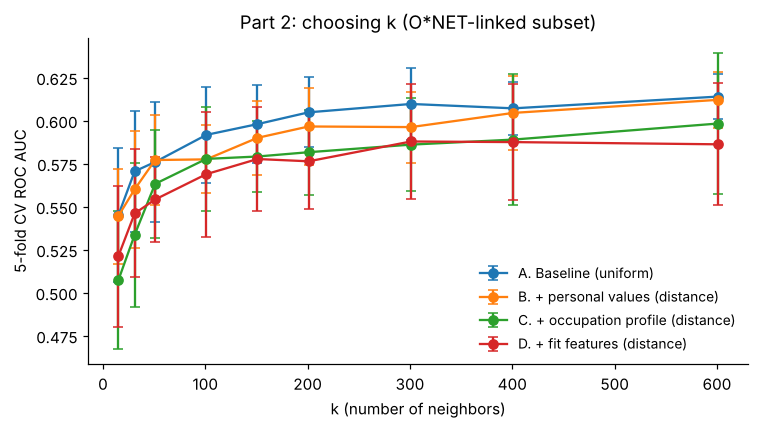

,ΔAUC,95% CI,share of bootstraps > 0
comparison,,,
B vs A,0.042,"[+0.001, +0.081]",0.980
C vs A,0.004,"[-0.046, +0.051]",0.554
D vs A,0.008,"[-0.051, +0.061]",0.600
D vs C: fit beyond occupation,0.004,"[-0.024, +0.033]",0.593


In [9]:
plot_k_curves(search_on, 'Part 2: choosing k (O*NET-linked subset)')
yt = y_on[test_o].to_numpy()
names = list(sets_on)
deltas_on = pd.DataFrame([paired_delta_auc(yt, probs_on[names[0]], probs_on[n], f'{n[:1]} vs A') for n in names[1:]] +
                         [paired_delta_auc(yt, probs_on[names[2]], probs_on[names[3]], 'D vs C: fit beyond occupation')]
                        ).set_index('comparison')
deltas_on

**Observation:** Two cautions before reading these numbers.

1. **The test set is small.** It has only 119 not-satisfied people, so the confidence intervals are about ±0.05 wide. Gaps of 0.01 to 0.02 between models are noise.
2. **CV and test disagree in places.** B's cross-validated AUC (0.612) is about equal to A's (0.614), but B is higher on the test set (0.668 vs. 0.626). The full-sample result in Part 1 is the more reliable read on personal values.

The CV curves flatten past k ≈ 300, so the grid edge (k = 601) doesn't change any conclusion.

The fit question is D against C: does comparing the person's values with the job's add anything beyond knowing the job? The answer is +0.004 [−0.024, +0.033], so no detectable effect for KNN. KNN gives every standardized column equal say in the distance, so six O*NET columns plus six gap columns mostly add noise around the baseline features. A logistic regression or tree model can learn to weight these columns, which makes them a fairer test of whether fit carries signal.

## 5. Where the best model makes mistakes

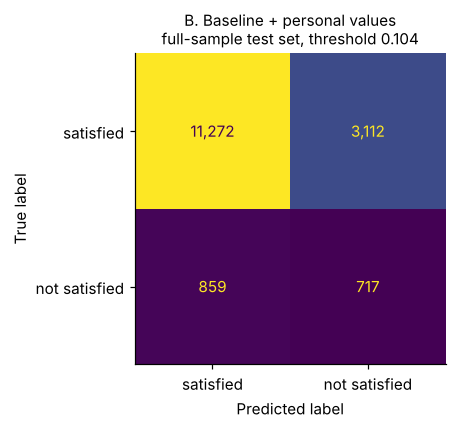

In [10]:
best_name = res_full['test AUC'].idxmax()
s = search_full[best_name]
pred = (probs_full[best_name] >= s.threshold_).astype(int)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(y_full[test_f], pred),
                       display_labels=['satisfied', 'not satisfied']).plot(ax=ax, colorbar=False, values_format=',')
ax.set_title(f'{best_name}\nfull-sample test set, threshold {s.threshold_:.3f}', fontsize=10)
plt.tight_layout(); plt.show()

**Observation:** At the threshold picked on training data (0.104), the model finds 717 of the 1,576 not-satisfied people in the test set (recall 45.5%). It also flags 3,112 satisfied people. So precision is 18.7%, about 1.9 times the 9.9% base rate. That's useful for ranking who might be at risk, not for confidently labeling individuals. Moving the threshold trades recall for precision.

## 6. Save results

In [11]:
out = pd.concat([res_full.assign(sample='full NSCG (79,800)'), res_on.assign(sample='O*NET subset')])
out.to_csv(RESULTS / 'knn_results.csv')
print('saved', (RESULTS / 'knn_results.csv').relative_to(ROOT))
out

saved results/knn_results.csv


,best k,weights,CV AUC,test AUC,AUC 95% CI,weighted AUC,PR AUC,threshold,precision,recall,F1,sample
model,,,,,,,,,,,,
A. Baseline,801,uniform,0.655,0.652,"[0.638, 0.667]",0.687,0.179,0.112,0.176,0.403,0.245,"full NSCG (79,800)"
B. Baseline + personal values,801,distance,0.677,0.680,"[0.667, 0.694]",0.699,0.191,0.104,0.187,0.455,0.265,"full NSCG (79,800)"
A. Baseline,601,uniform,0.614,0.626,"[0.573, 0.677]",0.684,0.154,0.080,0.133,0.613,0.219,O*NET subset
B. + personal values,601,distance,0.612,0.668,"[0.619, 0.715]",0.689,0.170,0.082,0.162,0.555,0.251,O*NET subset
C. + occupation profile,601,distance,0.598,0.630,"[0.577, 0.681]",0.573,0.155,0.081,0.150,0.445,0.225,O*NET subset
D. + fit features,301,distance,0.588,0.634,"[0.580, 0.684]",0.576,0.153,0.070,0.122,0.664,0.206,O*NET subset


## 7. Takeaways and next steps

**For the team write-up:**
- KNN, tuned by cross-validation (k ≈ 800, distance weighting), reaches a test AUC of 0.680 [0.667, 0.694] on the full NSCG sample using background factors plus personal work values.
- Personal work values add +0.028 AUC [+0.018, +0.038] over background factors alone.
- On the 25-occupation O*NET subset, occupation-level work values and the gap-based fit features did not improve KNN (ΔAUC +0.004 [−0.024, +0.033] for fit beyond the occupation profile).

**Limitations:**
- Only 25 occupations, and about 9% of respondents, are linked to O*NET so far. The O*NET Work Values ratings mostly date from 2008.
- The fit score here uses one mapping of NSCG items onto O*NET values (Section 4.1). Other mappings or scoring methods (Track B) could give different results.
- KNN can't use survey weights in training, and its accuracy depends on which columns go into the distance.
- NSCG covers only college graduates.

**Next steps:**
1. Rerun Part 2 once more occupations are linked. The code needs no changes.
2. Compare these KNN results with logistic regression and tree models on the same splits (same `SEED`), using `results/knn_results.csv`.
3. Try KNN on a smaller, chosen set of features, such as baseline plus `mean_abs_gap` only, to see whether fit shows up once the distance isn't diluted.
